# Fig. 3b: Example MCC units

[AI generated summary] Spike rasters and mean firing rates of the five example MCC units of Fig. 3b, for rewarded vs. unrewarded trials (left, aligned to feedback) and for the four levels of the foraging value (right, before feedback). The paper shows the mean firing rates.

**How to run:** set `DATA_PATH` in `popy/config.py`, then run all cells. Uses the behavior and the spike trains of the example sessions (`neural_data/`). Figures are saved in `figs/`.

Source data of the plotted panels are exported to `source_data/` (see `popy/source_data.py`).

---
# Setup

In [1]:
##% imports
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from time import time

from popy.io_tools import load_behavior, load_neural_data
from popy.behavior_data_tools import add_foraging_value, drop_time_fields, add_RL_values, add_switch_info, add_history_of_feedback
from popy.neural_data_tools import *
from popy.plotting.plotting_tools import plot_keypoints


from popy.config import COLORS, value_gradient
# fontsizes 8
plt.rcParams.update({'font.size': 8})

from helpers_units import get_data, _prepare_data

In [2]:
import os
from popy.config import FIGS_PATH
os.makedirs(FIGS_PATH, exist_ok=True)  # the figure panels are saved here

In [3]:
def plot_rates_with_raster(
    neural_data_original, 
    suptitle=None,
    paper_format=False,  # use paper format
    ):    

    neural_data = neural_data_original.copy()

    # get the coord names of interest and determine the number of plots to make
    coord_names = ['feedback', 'stay_value']  # get the coord names of interest
    n_plots = 2
    
    # Create figure and axes with no space between rows
    if paper_format:
        # fontsize 8
        plt.rcParams.update({'font.size': 8})  # set fontsize to 8
        h, w = 1, 1.5 * n_plots  # 3 cm height, 3 cm width per plot
        fig = plt.figure(figsize=(w, h))
    else:
        h, w = 3, 3*n_plots
        fig = plt.figure(figsize=(w, h))
    
    gs = fig.add_gridspec(2, n_plots, height_ratios=[1, .7], hspace=0)

    # Create axes arrays with shared axes
    axs = [[None for j in range(n_plots)] for i in range(2)]
    
    # First create the leftmost column
    axs[0][0] = fig.add_subplot(gs[0, 0])  # Top left
    axs[1][0] = fig.add_subplot(gs[1, 0])  # Bottom left
    plt.setp(axs[0][0].get_xticklabels(), visible=False)  # Hide only the tick labels, keep ticks

    # Then create the rest sharing both x and y axes
    for j in range(1, n_plots):
        axs[0][j] = fig.add_subplot(gs[0, j], sharey=axs[0][0])  # Top row
        axs[1][j] = fig.add_subplot(gs[1, j], sharey=axs[1][0])  # Bottom row
        plt.setp(axs[0][j].get_xticklabels(), visible=False)  # Hide only the tick labels, keep ticks

    if not suptitle is None:
        fig.suptitle(suptitle, style='italic')

    for i, coord_name in enumerate(coord_names):
        # get the variable and the conditions
        variable = coord_name

        unique_labels = np.unique(neural_data[coord_name].data)  # get the unique labels of all of the coords of interest
        unique_labels = unique_labels[~np.isnan(unique_labels)]  # remove nans
        
        if variable == 'feedback':
            COLORS_temp = COLORS
            label_encoding = {0: 'Unrewarded', 1: 'Rewarded'}  # encode the feedback labels
            time_window=(-.5, 2)
            legend_title='Feedback'
        elif variable == 'stay_value':
            COLORS_temp = value_gradient(len(unique_labels))
            label_encoding = {0:'<25%', 1:'25-50%', 2:'50-75%', 3:'>75%'}
            time_window=(-2, .5)
            legend_title='Value level'

        colors = {str(label): COLORS_temp[i] for i, label in enumerate(unique_labels)}  # color for each value level

        # prepare the data (sort trials by the coord_name, drop trials with nan labels)
        neural_data_temp = _prepare_data(neural_data, coord_name)

        time_vector = neural_data_temp.coords['time'].data  # get the time vector and the trial labels

        # plot raster with extent of x=time_vector and y=trial_labels
        ax_raster = axs[0][i]

        # Plot colored spikes
        # Convert spike trains to x,y coordinates
        spikes = np.where(neural_data_temp.spike_trains)
        trial_ids = spikes[0]
        spike_times = time_vector[spikes[1]]

        # Get colors for each spike based on trial type
        trial_colors = [colors[str(neural_data_temp[coord_name].sel(trial_id=neural_data_temp.trial_id.data[tid]).data)] for tid in trial_ids]  # get the color of the trial

        ax_raster.scatter(spike_times, trial_ids, marker='|', c=trial_colors, s=2.5, linewidth=0.6)
        
        ax_raster.set_ylabel('')
        
        ax_raster.set_yticks([])  # remove y ticks
        #ax_raster.legend(title=f'{coord_name.split("--")[0][1:]}', loc='center left', bbox_to_anchor=(1, 0.5))
        ax_raster.spines['bottom'].set_visible(False)

        # plot firing rate (that is the mean spike count) by value level
        ax_rate = axs[1][i]
        unique_labels_temp = np.unique(neural_data_temp[coord_name].data)  # set background color based on value level
        for label_temp in unique_labels_temp:
            curr_coord_ids = np.where(neural_data_temp[coord_name].data == label_temp)[0]  # get the non-nan indices
            curr_coord_trials = neural_data_temp.trial_id.data[curr_coord_ids]
            neural_data_currvalue = neural_data_temp.sel({'trial_id': curr_coord_trials})  # further select only the interesting units
            # rolling window spike count mean
            mean_rate = np.mean(neural_data_currvalue.firing_rates, axis=0)

            ax_rate.plot(time_vector, mean_rate, label=label_temp if label_encoding is None else label_encoding[label_temp], color=colors[str(label_temp)])
            
        if not paper_format:
            ax_rate.set_ylabel('Firing rate (Hz)')
            ax_rate.set_xlabel('Time from feedback (s)')
            # legend outside the plot
            ax_rate.legend(title=variable if legend_title is None else legend_title, frameon=False, loc='center left', bbox_to_anchor=(1, 0.5))
        # settings
        for ax in [ax_raster, ax_rate]:
            ax.axvline(0, color='black', lw=.7)  # plot the centering line
            ax.set_xlim(*time_window)
            # remove spines
            for spine in ['right', 'top']:
                ax.spines[spine].set_visible(False)

    if not paper_format:    
        plt.tight_layout()

    return fig, axs

---
# Fig. 3b, Example units

Set to NaN 11/47 units with trunctuated recordings, delay limit: 20 s.
 Invalid units: {'MCC_16_03', 'MCC_05_02', 'MCC_02_02', 'MCC_01_01', 'MCC_05_01', 'MCC_01_02', 'MCC_04_01', 'MCC_02_01', 'LPFC_03_03', 'MCC_11_02', 'MCC_03_01'}


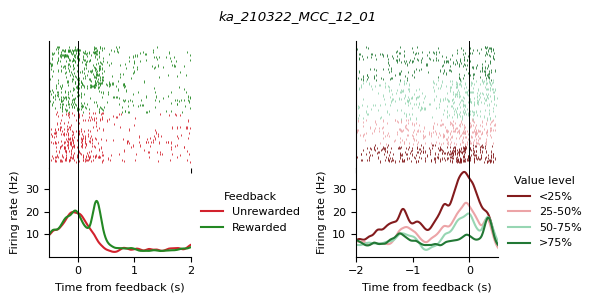

Set to NaN 14/38 units with trunctuated recordings, delay limit: 20 s.
 Invalid units: {'LPFC_10_01', 'MCC_05_02', 'LPFC_10_02', 'MCC_11_03', 'MCC_01_01', 'MCC_12_01', 'MCC_15_01', 'MCC_12_02', 'MCC_01_02', 'MCC_04_01', 'LPFC_07_01', 'MCC_11_02', 'MCC_03_01', 'MCC_10_02'}


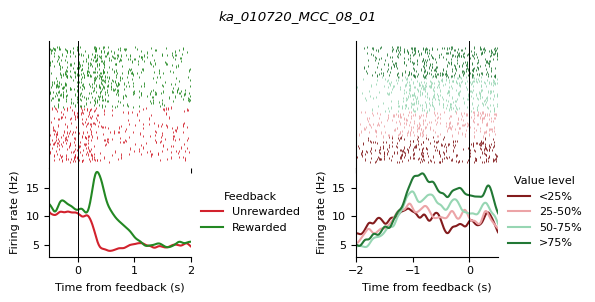

Set to NaN 4/40 units with trunctuated recordings, delay limit: 20 s.
 Invalid units: {'MCC_08_02', 'MCC_03_01', 'MCC_08_01', 'LPFC_15_03'}


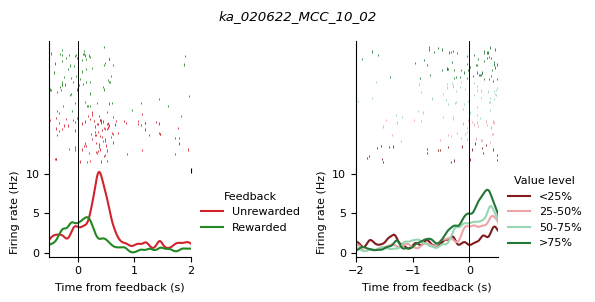

Set to NaN 3/32 units with trunctuated recordings, delay limit: 20 s.
 Invalid units: {'LPFC_14_01', 'LPFC_04_02', 'LPFC_04_01'}


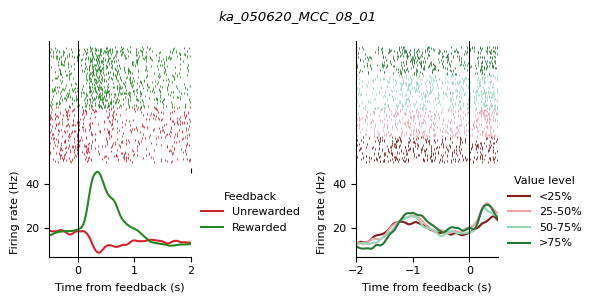

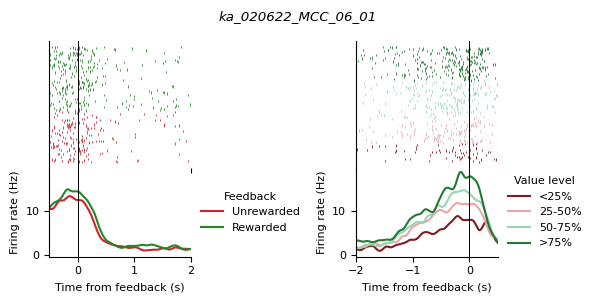

In [4]:
# example units of Fig. 3b (monkey_session_unit), from top to bottom
example_units = ['ka_210322_MCC_12_01', 'ka_010720_MCC_08_01', 'ka_020622_MCC_10_02', 'ka_050620_MCC_08_01', 'ka_020622_MCC_06_01']

datasets = {}
for example_unit in example_units:
    monkey, session = example_unit.split('_')[:2]
    unit_name = '_'.join(example_unit.split('_')[2:])

    # load data (once per session)
    if (monkey, session) not in datasets:
        datasets[(monkey, session)] = get_data(monkey, session)
    neural_data, neural_dataset = datasets[(monkey, session)]

    title = f'{neural_data.coords["monkey"].data[0]}_{neural_data.coords["session"].data[0]}_{unit_name}'

    fig, axs = plot_rates_with_raster(
        neural_dataset.sel({'unit': unit_name}),
        suptitle=title,
        )

    fig.savefig(os.path.join(FIGS_PATH, f'fig3b_{title}.svg'), dpi=300, bbox_inches='tight', transparent=True)
    plt.show()
    plt.close()

In [5]:
# Export source data (Figure 3b)
from popy.source_data import export_source_data
import pandas as pd

# mean firing rates as computed in plot_rates_with_raster (same data preparation), within the plotted time windows
sd_panels = {  # coord: (table title, plotted time window (s), curve names)
    'feedback': ('Left: rewarded vs. unrewarded trials', (-.5, 2), {0: 'Unrewarded', 1: 'Rewarded'}),
    'stay_value': ('Right: value levels', (-2, .5), {0: 'value <25%', 1: 'value 25-50%', 2: 'value 50-75%', 3: 'value >75%'}),
}
sd_curves = {coord_name: [] for coord_name in sd_panels}
sd_n_trials = []
for example_unit in example_units:
    sd_monkey, sd_session = example_unit.split('_')[:2]
    sd_unit_data = datasets[(sd_monkey, sd_session)][1].sel({'unit': '_'.join(example_unit.split('_')[2:])})
    for coord_name, (sd_title, sd_window, sd_names) in sd_panels.items():
        sd_data = _prepare_data(sd_unit_data, coord_name)
        sd_time = sd_data.coords['time'].data
        sd_visible = (sd_time >= sd_window[0] - 1e-6) & (sd_time <= sd_window[1] + 1e-6)
        for label in np.unique(sd_data[coord_name].data):
            sd_trials = sd_data.trial_id.data[np.where(sd_data[coord_name].data == label)[0]]
            sd_mean_rate = np.asarray(np.mean(sd_data.sel({'trial_id': sd_trials}).firing_rates, axis=0))
            sd_curves[coord_name].append(pd.Series(sd_mean_rate[sd_visible], index=np.round(sd_time[sd_visible], 3),
                                                   name=f'{example_unit}, {sd_names[label]} (Hz)'))
            sd_n_trials.append({'Unit': example_unit, 'Panel': sd_title.split(':')[0], 'Curve': sd_names[label],
                                'Number of trials': len(sd_trials)})

sd_tables = {}
for coord_name, (sd_title, sd_window, sd_names) in sd_panels.items():
    sd_df = pd.concat(sd_curves[coord_name], axis=1)
    sd_df.index.name = 'Time from feedback (s)'
    sd_tables[sd_title] = sd_df.reset_index()
sd_tables['Number of trials per curve'] = pd.DataFrame(sd_n_trials)

export_source_data(
    'Figure 3b', sd_tables,
    'Mean firing rate (Hz; spike trains convolved with a Gaussian kernel of SD 50 ms, sampled every 10 ms) of the five '
    'example MCC units of monkey KA (top to bottom as in the figure; unit IDs: monkey_session_unit), averaged over trials, '
    'aligned to feedback (time 0), within the plotted windows. Left: rewarded vs. unrewarded trials; right: trials grouped '
    'by the foraging-model value before feedback (4 levels: <0.25, 0.25-0.5, 0.5-0.75, >0.75). No error bars; number of '
    'trials per curve in the last table. Spike rasters are not included.'
)

Figure 3b: source data saved (251 rows, 251 rows, 30 rows)
